# Collab CENTAUR & SEED-FD: Somalia droughts

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a timeseries for a subset of the dataset for Somalia. 
> Keune, J., F. Di Giuseppe, C. Barnard, E. Damasio da Costa, and F. Wetterhall (2025): ERA5--Drought: Global drought indicators based on ECMWF reanalysis. Sci Data 12, 616 (2025). https://doi.org/10.1038/s41597-025-04896-y.

## Setup and Settings

#### Load libraries

In [1]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [2]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.nan
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [3]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 1950
yyyy_end  = 2026
indicator = "SPEI"
window    = 12
yyyy      = 2026
mm        = "03"
dataset   = "era5"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
#ipath_era5t= f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
country   = "Somalia"

In [4]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')[:-8]
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(dates)
print(dates.size)

DatetimeIndex(['1950-01-31', '1950-02-28', '1950-03-31', '1950-04-30',
               '1950-05-31', '1950-06-30', '1950-07-31', '1950-08-31',
               '1950-09-30', '1950-10-31',
               ...
               '2024-07-31', '2024-08-31', '2024-09-30', '2024-10-31',
               '2024-11-30', '2024-12-31', '2025-01-31', '2025-02-28',
               '2025-03-31', '2025-04-30'],
              dtype='datetime64[ns]', length=904, freq='ME')
904


### Landmask and area

In [5]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

/usr/local/apps/python3/3.12.9-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.39.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Country / Region of interest

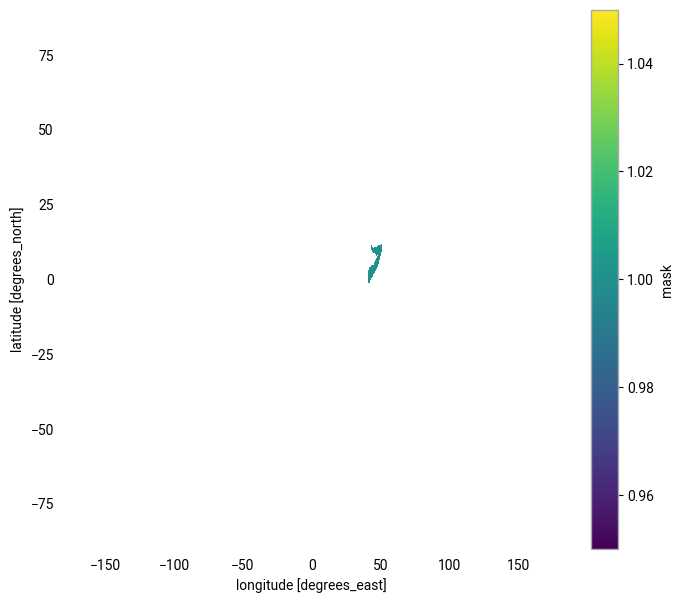

In [6]:
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].plot()
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[["Somalia","Somaliland"]].mask(lmask.lon, lmask.lat)
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

In [7]:
lon1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][0])
lon2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][2])
lat1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][1])
lat2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][3])
print(f"Bounding box: lats {lat1} to {lat2}, lons {lon1} to {lon2}")

Bounding box: lats -2 to 13, lons 40 to 52


## Drought indices

### Read drought index 

In [8]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
print(filelist[:20])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
print(drought_index[window])

['/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510101/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195101.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510201/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195102.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510301/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195103.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510401/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195104.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510501/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195105.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510601/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_195106.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19510701/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2

### Mask drought index

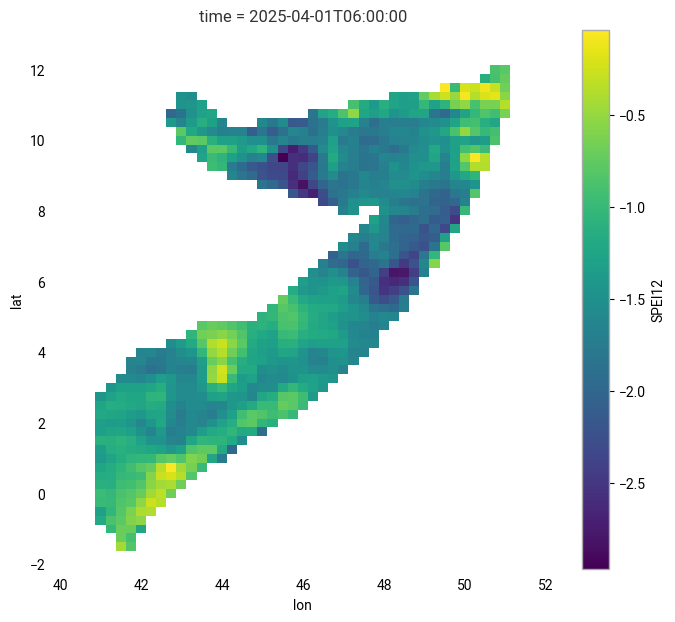

In [9]:
masked_drought_index = drought_index[window] * mask
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan
mask_cut = mask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
#area_2d.plot()
#area_2d_adj.plot()

### Calculate area in drought

In [10]:
#robinson = ccrs.Robinson().proj4_init

In [11]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (mask_cut*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries of area in drought

In [12]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']

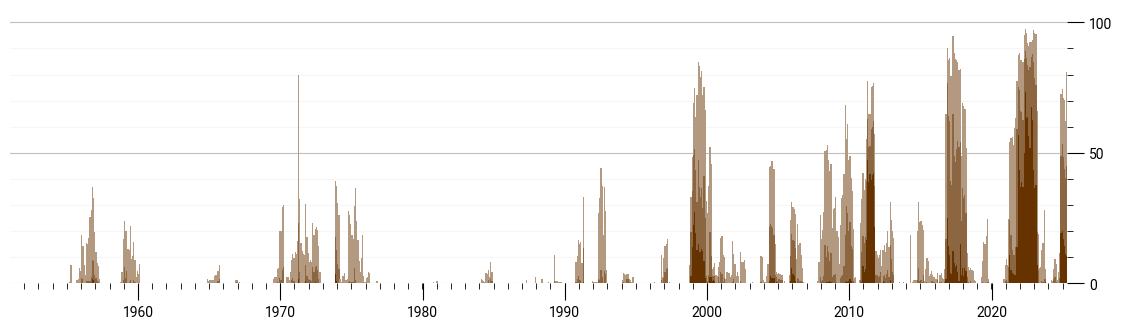

In [13]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
#title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
#fig.suptitle(f"{title1} | Percent of {country} in drought ({indicator}-{window})", fontsize=22)
#fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
#ax1.set_ylabel("Area in drought [%]", size=18)
#ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
#ax1.spines['top'].set_visible(False)
#ax1.spines['right'].set_visible(False)
#ax1.spines['left'].set_visible(False)
#ax1.tick_params(axis='y', colors='dimgray')
#ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='black')
#ax1.xaxis.label.set_color('None')
#ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
# Major ticks every 20, minor ticks every 5
#https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
ax1.xaxis.tick_bottom()
# And a corresponding grid
#ax1.grid(which='minor')
# Or if you want different settings for the grids:
#ax.grid(which='minor', alpha=0.2)
#ax.grid(which='major', alpha=0.5)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
#for tick in ax1.get_xticklabels():
#    tick.set_rotation(45)
    
plt.savefig(f"figures/{country}_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

### Plot maps for specific events

time
2022-05-01 06:00:00    97.362703
2022-12-01 06:00:00    97.239371
2022-06-01 06:00:00    95.857803
2023-01-01 06:00:00    95.736958
2023-02-01 06:00:00    95.554077
2022-04-01 06:00:00    95.122073
2017-04-01 06:00:00    94.809928
2022-11-01 06:00:00    93.179987
2022-10-01 06:00:00    92.533784
2022-09-01 06:00:00    92.332457
dtype: float64
[np.int64(856), np.int64(863), np.int64(857), np.int64(864), np.int64(865), np.int64(855), np.int64(795), np.int64(862), np.int64(861), np.int64(860)]
[np.int64(856), np.int64(863), np.int64(857), np.int64(864), np.int64(865), np.int64(855), np.int64(795), np.int64(862), np.int64(861), np.int64(860), np.int64(729), np.int64(602)]
2022-05


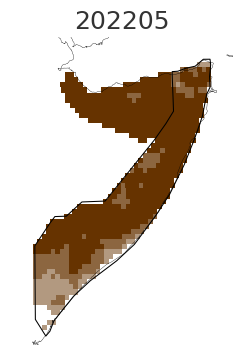

2022-12


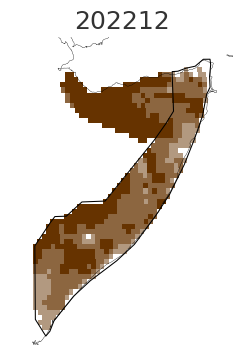

2022-06


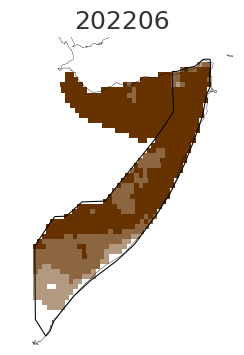

2023-01


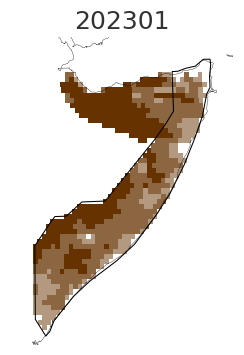

2023-02


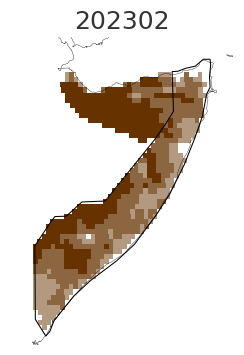

2022-04


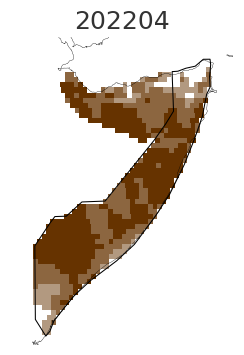

2017-04


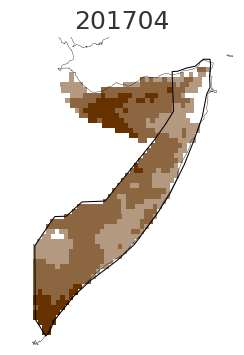

2022-11


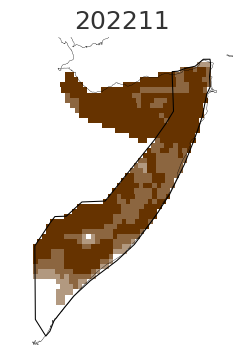

2022-10


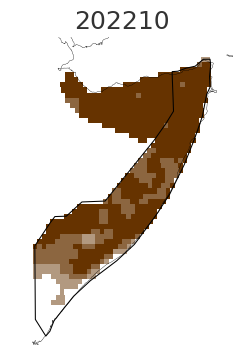

2022-09


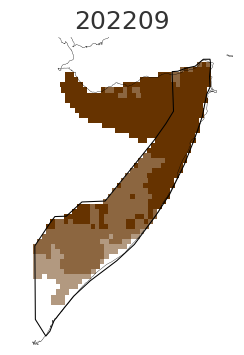

2011-10


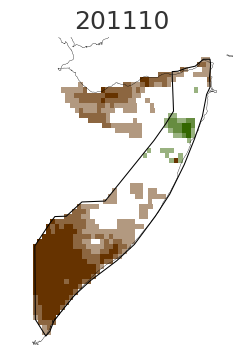

2001-03


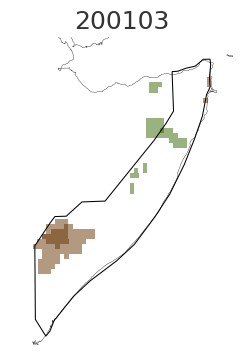

In [14]:
countries = shapereader.natural_earth(resolution='110m',
                              category='cultural',
                              name='admin_0_countries')

highlight_countries = [country]
for icountry in shapereader.Reader(countries).records():
    if icountry.attributes['ADMIN'] in highlight_countries:
        country_geom = icountry.geometry
        
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 16}
plt.rc('font', **font)

n = 10
nmax_indices = []
print(apidata.sum(axis=1).sort_values(ascending=False)[0:10,])
for i in range(n):
    nmax_indices.append(np.flatnonzero(apidata.index == apidata.sum(axis=1).sort_values(ascending=False).index[i])[0])
print(nmax_indices)
# manually add 1992-11
nmax_indices.append(np.where(apidata.index.strftime("%Y-%m") == "2011-10")[0][0])
nmax_indices.append(np.where(apidata.index.strftime("%Y-%m") == "2001-03")[0][0])
print(nmax_indices)

#i = 0
for itime in nmax_indices:
    toplot       = masked_drought_index.isel(time=itime)[f'{indicator}{window}']#['SPEI12'] * nutsmask_3d_xr.isel(time=itime)
    print(str(toplot.time.values)[:7])
    
    plt.figure(figsize=(4.5, 4));
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    ax.coastlines(color='black', lw=0.25)
    toplot.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=mycollisthex,
                              levels=mylevels)
    #ax.set_xlim([lon1,lon2])
    #ax.set_ylim([lat1,lat2])
    
    #title1 = r"$\bf{" + f"{string.ascii_lowercase[i]}" + "}$"
    #ax.set_title(f"{title1} | {str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    ax.set_title(f"{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    
    #ax.add_feature(cartopy.feature.BORDERS, color='black', lw=0.3)
    ax.add_geometries([country_geom], crs=ccrs.PlateCarree(), edgecolor='black', facecolor="None", linewidth=0.75)
    #plt.savefig(f"figures/{country}_{string.ascii_lowercase[i]}_map_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.pdf", dpi=300, format=None, metadata=None,
    plt.savefig(f"figures/{country}_map_{indicator}{window}_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            #facecolor='auto', edgecolor='auto',
            transparent=True,
            backend=None)
    plt.show()
    #i += 1
    

In [16]:
countries = shapereader.natural_earth(resolution='110m',
                              category='cultural',
                              name='admin_0_countries')

highlight_countries = ["Somalia","Somaliland"]
for icountry in shapereader.Reader(countries).records():
    if icountry.attributes['ADMIN'] in highlight_countries:
        country_geom = icountry.geometry
        
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 16}
plt.rc('font', **font)

n = 24
istart = np.where(apidata.index.strftime("%Y-%m") == "2021-10")[0]
#nmax_indices.append(np.where(apidata.index.strftime("%Y-%m") == "2001-03")[0][0])
#print(nmax_indices)


plt.figure(figsize=(20, 16))
plt.subplots_adjust(hspace=0.25)
plt.suptitle("SPEI-12", fontsize=18, y=0.95)

for itime in range(n):
    
    toplot       = masked_drought_index.isel(time=istart + itime)[f'{indicator}{window}']
    print(str(toplot.time.values)[:7])
    
    #plt.figure(figsize=(4.5, 4));
    ax = plt.subplot(3, 4, n + 1)
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    ax.coastlines(color='black', lw=0.25)
    toplot.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=mycollisthex,
                              levels=mylevels)
    ax.set_title(f"{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    ax.add_geometries([country_geom], crs=ccrs.PlateCarree(), edgecolor='black', facecolor="None", linewidth=0.75)

plt.savefig(f"figures/{country}_map_{indicator}{window}_subplots.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            #facecolor='auto', edgecolor='auto',
            transparent=True,
            backend=None)
plt.show()
    #i += 1
    

NameError: name 'apidata' is not defined

## Drought updates over Horn of Africa

In [48]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

In [90]:
ref_syyyy = 1991
ref_eyyyy = 2020
indicator = "SPI"
window    = 36
yyyy      = 2025
mm        = "04"
dataset   = "era5t"
stream    = "moda"
distribut = "gamma" #"genlogistic"
ifile_name= f"{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{yyyy}{str(mm).zfill(2)}.nc"
# new versions
#ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/era5/{yyyy}{mm}01/hr"
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/era5t/{yyyy}{mm}01/hr"
ifile     = f"{ipath}/{ifile_name}"

In [91]:
drought_2d = xr.open_dataset(ifile)
print(drought_2d)
drought_2d_masked = xr.where(drought_2d[f'{indicator}{window}'] == -9999, np.nan, drought_2d[f'{indicator}{window}'])

<xarray.Dataset> Size: 8MB
Dimensions:  (time: 1, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8B 2025-04-01T06:00:00
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    SPI36    (time, lat, lon) float64 8MB ...
Attributes: (12/17)
    title:                   SPI36
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 03/05/2025 00:13:43 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    extent:                  -180,-90,180,90
    resolution:              0.25x0.25
    climate_start_date:      1991-01-01
    climate_end_date:        2020-12-31
    frequency:               Monthly
    contact_person:          support@ecmwf.in

In [92]:
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)
drought_2d_masked = xr.where( (bmask['barren_mask'][0,:,:] == 1) & (~np.isnan(drought_2d_masked)) , -9999, drought_2d_masked)

In [93]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

def hex2rgb(hexs):
   return tuple(int(hexs[i:i+2], 16)/255 for i in (0, 2, 4))

countries = shapereader.natural_earth(resolution='110m',
                              category='cultural',
                              name='admin_0_countries')

def worldmap_drought(data_2d, 
                     collist_hex, 
                     levels,
                     legnames,
                     plot_borders=False,
                     highlight_countries=["Somalia","Ethiopia","Kenya"],
                     figname="figures/SPEI12_HOA_19000000.png",
                     latlines=[-30,30], plot_latlines=False, mytitle=""):

    plt.figure(figsize=(9, 4));
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    ax.coastlines(color='black', lw=0.25)
    data_2d.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=collist_hex,
                              levels=levels,
                              vmin=-3, vmax=3)
    ax.set_title(mytitle)

    # horizontal lat-lines
    if plot_latlines:
        geodetic = ccrs.Geodetic()
        robinson = ccrs.Robinson()
        for ilat in latlines:
            ilon_1, ilat_1 = robinson.transform_point(-179, ilat, geodetic)
            ilon_2, ilat_2 = robinson.transform_point(+179, ilat, geodetic)
            ax.plot([ilon_1, ilon_2], [ilat_1, ilat_2], color='grey', linewidth=0.5, transform=robinson, linestyle=':')

    #ax.set_extent([-170000, 180, -50, 82]) # (x0, x1, y0, y1) # GLOBAL
    ax.set_extent([20, 60, -10, 15]) # (x0, x1, y0, y1)
    if plot_borders:
        ax.add_feature(cartopy.feature.BORDERS, color='black', lw=0.3)
    if len(highlight_countries) != 0:
        countries = shapereader.natural_earth(resolution='110m', category='cultural', name='admin_0_countries')
        for country in shapereader.Reader(countries).records():
            if country.attributes['ADMIN'] in highlight_countries:
                #country_reproj = country.to_crs(ccrs.Robinson()).geometry
                ax.add_geometries([country.geometry], edgecolor='black', facecolor="None", linewidth=0.85, crs=ccrs.PlateCarree())
        
    legend_elements = []
    for i in range(len(legnames)):
        legend_elements.append(Line2D([0], [0], marker='s', color='w', label=legnames[i], markerfacecolor=hex2rgb(collist_hex[i][1:]), markersize=8))
    plt.legend(handles=legend_elements, fontsize="8", loc ="lower left", ncol=1)

    plt.tight_layout()
    #plt.subplots_adjust(bottom=0.025, hspace=0.5, wspace=0.05)
    plt.savefig(figname, format=None, metadata=None,
                bbox_inches=None, pad_inches=0.1, dpi=300,
                facecolor='auto', edgecolor='auto',
                backend=None)
    plt.show()

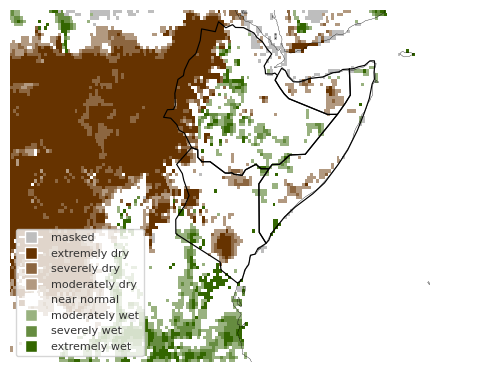

In [94]:
worldmap_drought(drought_2d_masked, 
                 collist_hex = mycollisthex, 
                 #levels = [-10000].append(mylevels),
                 #legnames = ["masked"].append(legnames),
                 levels = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000],
                 legnames = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
                 plot_borders=False,
                 highlight_countries = ["Somalia", "Somaliland", "Ethiopia", "Kenya"],
                 figname = f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}_HOA.png",
                 latlines = [-30,30],
                 plot_latlines =False, 
                 mytitle       = "")